# Model Comparison: Decision Tree vs PSTH vs RBF SVM

Load saved results from the three classifiers and compare:
1. **PCA vs No PCA** (MCCV 10 runs)
2. **Generalized vs Subject-specific** (MCCV 10 runs)

**Note:** Run `decision_tree.ipynb`, `psth_classifier.ipynb`, and `rbf_svm.ipynb` first to generate the result files.

In [6]:
import json
import numpy as np
import matplotlib.pyplot as plt
import os

# Load results from all three models
results_dir = "model_results"
model_files = {
    "Decision Tree": "decision_tree_results.json",
    "PSTH": "psth_classifier_results.json",
    "RBF SVM": "rbf_svm_results.json",
}

results = {}
for name, fname in model_files.items():
    path = os.path.join(results_dir, fname)
    if os.path.exists(path):
        with open(path) as f:
            results[name] = json.load(f)
        print(f"Loaded {name}")
    else:
        print(f"Warning: {path} not found. Run the corresponding notebook first.")

if not results:
    raise FileNotFoundError("No result files found. Run decision_tree, psth_classifier, and rbf_svm notebooks first.")

Loaded Decision Tree
Loaded PSTH
Loaded RBF SVM


In [7]:
# Extract means and stds for each model
from scipy import stats

def get_mean_std(arr):
    return np.mean(arr), np.std(arr)

def sig_marker(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns"

model_names = list(results.keys())
n_models = len(model_names)
width = 0.25
colors = ["#3498db", "#2ecc71", "#e74c3c"]  # blue, green, red

## Figure 1: PCA vs No PCA

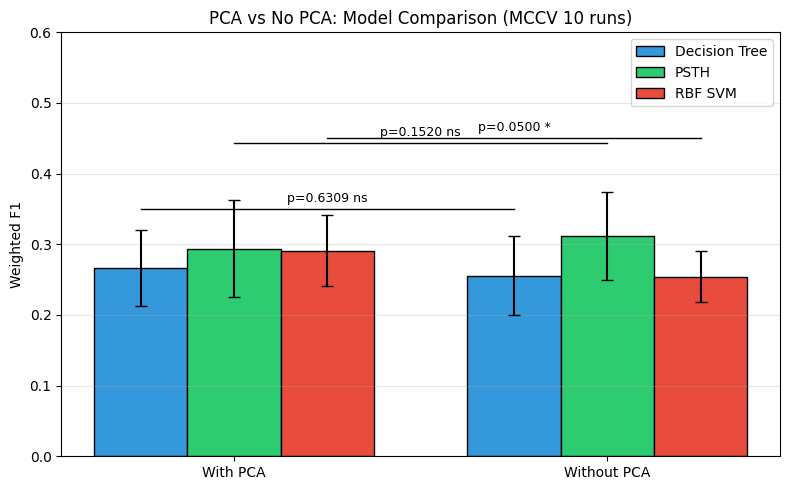

In [8]:
# Figure 1: PCA vs No PCA - grouped bars (3 models per category) with significance by model
fig, ax = plt.subplots(figsize=(8, 5))

x_cats = np.arange(2)  # With PCA, Without PCA
multipliers = np.arange(n_models) - (n_models - 1) / 2  # center bars: [-1, 0, 1] for 3 models

for i, name in enumerate(model_names):
    r = results[name]
    mean_with, std_with = get_mean_std(r["f1_with_pca"])
    mean_no, std_no = get_mean_std(r["f1_no_pca"])
    offset = width * multipliers[i]
    ax.bar(
        x_cats + offset,
        [mean_with, mean_no],
        width,
        yerr=[std_with, std_no],
        capsize=4,
        label=name,
        color=colors[i % len(colors)],
        edgecolor="black",
    )

# Paired t-test and significance bracket for each model
for i, name in enumerate(model_names):
    r = results[name]
    _, p_val = stats.ttest_rel(r["f1_with_pca"], r["f1_no_pca"])
    sig = sig_marker(p_val)
    offset = width * multipliers[i]
    x_left = x_cats[0] + offset
    x_right = x_cats[1] + offset
    ymax = max(
        np.mean(r["f1_with_pca"]) + np.std(r["f1_with_pca"]),
        np.mean(r["f1_no_pca"]) + np.std(r["f1_no_pca"]),
    ) + 0.03 + 0.04 * i
    ax.plot([x_left, x_right], [ymax, ymax], "k-", lw=1)
    ax.text((x_left + x_right) / 2, ymax + 0.01, f"p={p_val:.4f} {sig}", ha="center", fontsize=9)

ax.set_xticks(x_cats)
ax.set_xticklabels(["With PCA", "Without PCA"])
ax.set_ylabel("Weighted F1")
ax.set_title("PCA vs No PCA: Model Comparison (MCCV 10 runs)")
ax.legend(loc="upper right")
ax.set_ylim(0, 0.6)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Figure 2: Generalized vs Subject-specific

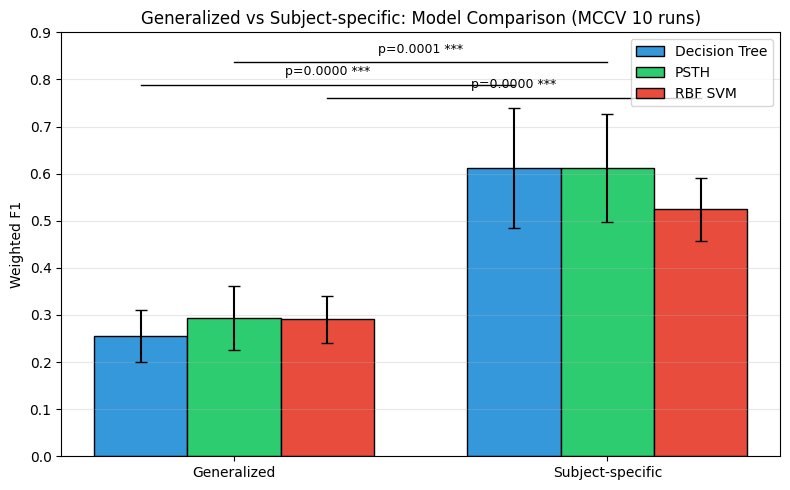

In [9]:
# Figure 2: Generalized vs Subject-specific - grouped bars (3 models per category) with significance by model
fig, ax = plt.subplots(figsize=(8, 5))

x_cats = np.arange(2)  # Generalized, Subject-specific
multipliers = np.arange(n_models) - (n_models - 1) / 2

for i, name in enumerate(model_names):
    r = results[name]
    mean_gen, std_gen = get_mean_std(r["f1_generalized"])
    mean_subj, std_subj = get_mean_std(r["f1_subject_specific"])
    offset = width * multipliers[i]
    ax.bar(
        x_cats + offset,
        [mean_gen, mean_subj],
        width,
        yerr=[std_gen, std_subj],
        capsize=4,
        label=name,
        color=colors[i % len(colors)],
        edgecolor="black",
    )

# Paired t-test and significance bracket for each model
for i, name in enumerate(model_names):
    r = results[name]
    _, p_val = stats.ttest_rel(r["f1_generalized"], r["f1_subject_specific"])
    sig = sig_marker(p_val)
    offset = width * multipliers[i]
    x_left = x_cats[0] + offset
    x_right = x_cats[1] + offset
    ymax = max(
        np.mean(r["f1_generalized"]) + np.std(r["f1_generalized"]),
        np.mean(r["f1_subject_specific"]) + np.std(r["f1_subject_specific"]),
    ) + 0.05 + 0.06 * i
    ax.plot([x_left, x_right], [ymax, ymax], "k-", lw=1)
    ax.text((x_left + x_right) / 2, ymax + 0.02, f"p={p_val:.4f} {sig}", ha="center", fontsize=9)

ax.set_xticks(x_cats)
ax.set_xticklabels(["Generalized", "Subject-specific"])
ax.set_ylabel("Weighted F1")
ax.set_title("Generalized vs Subject-specific: Model Comparison (MCCV 10 runs)")
ax.legend(loc="upper right")
ax.set_ylim(0, 0.9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Summary table
print("--- PCA vs No PCA (mean ± std) ---")
for name in model_names:
    r = results[name]
    m1, s1 = get_mean_std(r["f1_with_pca"])
    m2, s2 = get_mean_std(r["f1_no_pca"])
    print(f"{name}: With PCA={m1:.4f}±{s1:.4f}, No PCA={m2:.4f}±{s2:.4f}")

print("\n--- Generalized vs Subject-specific (mean ± std) ---")
for name in model_names:
    r = results[name]
    m1, s1 = get_mean_std(r["f1_generalized"])
    m2, s2 = get_mean_std(r["f1_subject_specific"])
    print(f"{name}: Generalized={m1:.4f}±{s1:.4f}, Subject-specific={m2:.4f}±{s2:.4f}")

--- PCA vs No PCA (mean ± std) ---
Decision Tree: With PCA=0.2664±0.0532, No PCA=0.2556±0.0557
PSTH: With PCA=0.2938±0.0683, No PCA=0.3116±0.0623
RBF SVM: With PCA=0.2908±0.0500, No PCA=0.2539±0.0361

--- Generalized vs Subject-specific (mean ± std) ---
Decision Tree: Generalized=0.2556±0.0557, Subject-specific=0.6113±0.1276
PSTH: Generalized=0.2938±0.0683, Subject-specific=0.6121±0.1141
RBF SVM: Generalized=0.2908±0.0500, Subject-specific=0.5243±0.0667
